# Hierarchical Clustering: a family tree of customers

**Goal.** Build a hierarchy of clusters, without choosing `k` in advance.

**The algorithm (agglomerative).** Each sample begins as its own cluster, and the two closest clusters are merged repeatedly.
**Ward linkage** merges the pair that increases the within-cluster variance the least.
The history of merges is drawn as a **dendrogram**.

**The dataset.** *Wholesale Customers* (UCI): yearly spending of 440 clients of a distributor in 6 product categories. There are no labels.

In [1]:
# SETUP: install any package this notebook needs but your Python does not have.
# It uses the same Python that runs this notebook, so it also works on Windows
# inside a virtual environment or Anaconda.
import importlib.util
import subprocess
import sys

required = {  # import name -> pip package name
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",
    "certifi": "certifi",
    "scipy": "scipy"
}
missing = [pip for module, pip in required.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("All required packages are already installed.")

All required packages are already installed.


In [2]:
# A consistent look for every figure, and a fixed random seed so that
# running the notebook twice gives the same numbers.
import warnings
import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

PURPLE, BLUE, GREEN, ORANGE, RED = "#5A28C8", "#476ADD", "#00A651", "#F28C28", "#E0344B"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 12, "axes.titleweight": "bold", "axes.titlecolor": PURPLE,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

## 1. Get the data

In [3]:
# DOWNLOAD THE DATASET
# Files are stored next to this notebook in a "data" folder, and are only
# downloaded the first time. pathlib builds correct paths on Windows.
#
# Why certifi? Some Windows machines have an out-of-date certificate store and
# fail with CERTIFICATE_VERIFY_FAILED. certifi ships an up-to-date list of trusted
# authorities, so the secure connection is still fully verified.
import shutil
import ssl
import urllib.request
import zipfile
from pathlib import Path

import certifi

def download(url, destination):
    """Download url to destination unless the file already exists."""
    destination = Path(destination)
    if destination.exists():
        print("Already downloaded:", destination)
        return destination
    destination.parent.mkdir(parents=True, exist_ok=True)
    print("Downloading:", url)
    context = ssl.create_default_context(cafile=certifi.where())
    request = urllib.request.Request(url, headers={"User-Agent": "python"})
    temporary = destination.with_suffix(destination.suffix + ".part")
    with urllib.request.urlopen(request, context=context, timeout=600) as response, open(temporary, "wb") as output:
        shutil.copyfileobj(response, output)
    temporary.replace(destination)  # only a complete file gets the final name
    print("Saved:", destination, f"({destination.stat().st_size / 1e6:.1f} MB)")
    return destination

DATA_DIR = Path("data") / "wholesale"
archive = download("https://archive.ics.uci.edu/static/public/292/wholesale+customers.zip", DATA_DIR / "dataset.zip")
with zipfile.ZipFile(archive) as z:
    z.extractall(DATA_DIR)
print("Files:", [p.name for p in DATA_DIR.rglob("*") if p.is_file()][:10])

Already downloaded: data\wholesale\dataset.zip
Files: ['dataset.zip', 'Wholesale customers data.csv']


In [4]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

df = pd.read_csv(DATA_DIR / "Wholesale customers data.csv")
spending = df[["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]]

# Spending is heavily skewed: a few customers buy far more than the rest.
# The logarithm reduces that skew, then all columns are put on the same scale.
X = StandardScaler().fit_transform(np.log1p(spending))
print("Shape:", X.shape)

Shape: (440, 6)


## 2. Build the hierarchy

In [5]:
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage

tree = linkage(X, method="ward")
print("Number of merges:", len(tree))

Number of merges: 439


## 3. Cut the tree into k clusters and compare the scores

In [6]:
from sklearn.metrics import davies_bouldin_score, silhouette_score

k_values = list(range(2, 11))
silhouette = [silhouette_score(X, fcluster(tree, k, criterion="maxclust")) for k in k_values]
best_k = k_values[int(np.argmax(silhouette))]
labels = fcluster(tree, best_k, criterion="maxclust") - 1
sil, db = silhouette_score(X, labels), davies_bouldin_score(X, labels)
print(f"Best k = {best_k} | Silhouette = {sil:.3f} | Davies-Bouldin = {db:.3f}")
print("Customers per cluster:", np.bincount(labels))

Best k = 2 | Silhouette = 0.258 | Davies-Bouldin = 1.600
Customers per cluster: [262 178]


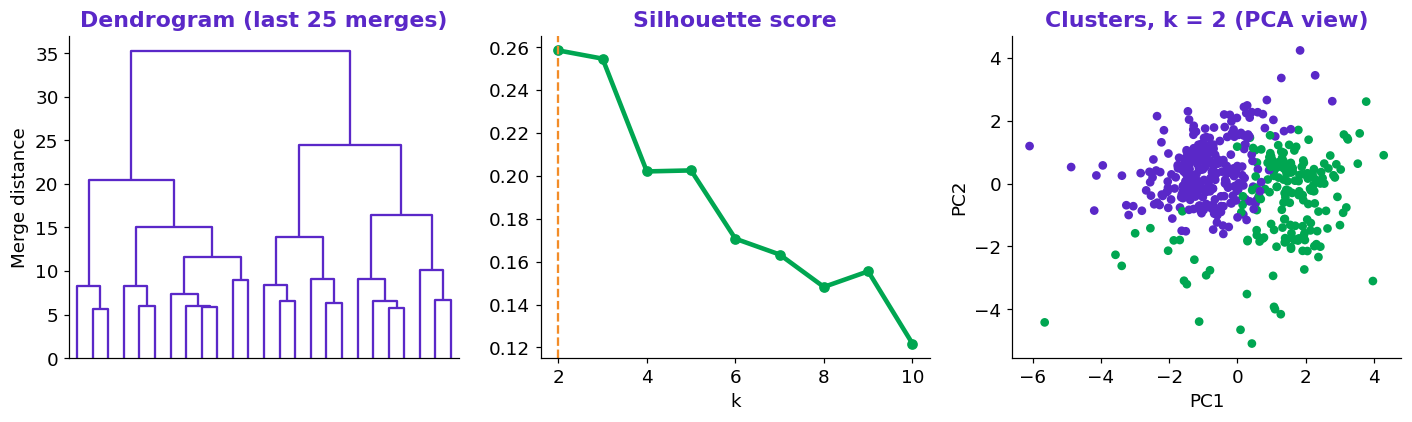

In [7]:
from sklearn.decomposition import PCA

points = PCA(n_components=2, random_state=SEED).fit_transform(X)
colors = np.array([PURPLE, GREEN, ORANGE, BLUE, RED, "gray", "black", "pink", "brown", "cyan"])

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
dendrogram(tree, truncate_mode="lastp", p=25, ax=ax[0], no_labels=True, color_threshold=0, above_threshold_color=PURPLE)
ax[0].set(title="Dendrogram (last 25 merges)", ylabel="Merge distance")
ax[1].plot(k_values, silhouette, color=GREEN, lw=3, marker="o")
ax[1].axvline(best_k, color=ORANGE, ls="--")
ax[1].set(title="Silhouette score", xlabel="k")
ax[2].scatter(points[:, 0], points[:, 1], c=colors[labels], s=22)
ax[2].set(title=f"Clusters, k = {best_k} (PCA view)", xlabel="PC1", ylabel="PC2")
fig.tight_layout()
plt.show()

In [8]:
# SAVE THE RESULTS. The figure and the metrics are written to a "results" folder.
# These exact files are what the course slides show.
import json

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)
fig.savefig(results_dir / "10_hierarchical_clustering.png", dpi=170, bbox_inches="tight", facecolor="white")

results = {
    "model": "Hierarchical Clustering",
    "dataset": "Wholesale Customers (UCI)",
    "n_samples": int(len(df)),
    "metrics": {"Best k": best_k, "Silhouette": round(float(sil), 3), "Davies-Bouldin": round(float(db), 3)},
}
(results_dir / "10_hierarchical_clustering.json").write_text(json.dumps(results, indent=2), encoding="utf-8")
print(json.dumps(results, indent=2))

{
  "model": "Hierarchical Clustering",
  "dataset": "Wholesale Customers (UCI)",
  "n_samples": 440,
  "metrics": {
    "Best k": 2,
    "Silhouette": 0.258,
    "Davies-Bouldin": 1.6
  }
}


## What to remember
- The dendrogram shows structure at every scale.
- Memory use grows with the square of the sample count, so it suits small to medium datasets.